# Fruit Freshness Detection — Complete Fixed Notebook
### All issues fixed. Run 1 → 2 → 3 → 4 → 5 in order.
**Runtime → Change runtime type → T4 GPU → Save (before running)**

**Fixes in this version:**
- GradCAM: original logic + one `int()` fix (proven working)
- DRS: 10 images per class (80 total, not 8)
- Stability: all 16 classes including rotten (not 6 fresh only)
- Feature analysis: fresh + rotten, entropy concentration (not broken percentile)
- Hybrid: all 640 samples + majority voting compared
- Binary models: evaluated inside this notebook
- ECS: mean confidence across all 16 predictions

In [ ]:
import os, json, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import cv2
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense
from collections import Counter
warnings.filterwarnings('ignore')

print('TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print('GPU:', gpus[0].name)
else:
    print('WARNING: No GPU — go Runtime > Change runtime type > T4 GPU > Save')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)
print('Drive mounted')

# Patch Dense layer for Keras version compatibility
_orig_dense_cfg = Dense.from_config.__func__
@classmethod
def _patched_dense_cfg(cls, config):
    config.pop('quantization_config', None)
    return _orig_dense_cfg(cls, config)
Dense.from_config = _patched_dense_cfg
print('Dense layer patched')

# ── Config ────────────────────────────────────────────────────────
MODEL_DIR       = '/content/drive/MyDrive/freshness_runtime_models'
DRIVE_TEST_PATH = '/content/drive/MyDrive/Mendeley_16Class_Dataset/test'
LOCAL_TEST_PATH = '/content/test'
SAVE_DIR        = '/content/drive/MyDrive/freshness_results_fixed'
IMG_SIZE        = (224, 224)
GRADCAM_LAYER   = 'Conv_1'
DRS_PER_CLASS   = 10   # 10 images x 8 fresh classes = 80 total
FEAT_PER_CLASS  = 10   # 10 images x 16 classes = 160 total

MULTICLASS_MODELS = [
    'MobileNet_16_Frozen.keras',
    'MobileNet_16_Finetuned.keras',
    'Fusion_Model.keras',
]
BINARY_MODELS = [
    'BaseCNN_Original.keras',
    'BaseCNN_Augmented.keras',
    'ResNet_Binary.keras',
    'MobileNet_Binary..keras',
]
os.makedirs(SAVE_DIR, exist_ok=True)
print(f'Results will be saved to: {SAVE_DIR}')

# ── Copy dataset to local storage ─────────────────────────────────
if os.path.exists(LOCAL_TEST_PATH) and len(os.listdir(LOCAL_TEST_PATH)) > 0:
    print('Dataset already at /content/test')
else:
    print('Copying dataset from Drive...')
    shutil.copytree(DRIVE_TEST_PATH, LOCAL_TEST_PATH)
    print('Copy done')

# ── Verify ────────────────────────────────────────────────────────
class_dirs = sorted([d for d in os.listdir(LOCAL_TEST_PATH)
                     if os.path.isdir(os.path.join(LOCAL_TEST_PATH, d))])
total = 0
print(f'  {"Class":<26} {"Images":>8}')
print('  ' + '-'*36)
for c in class_dirs:
    n = len([f for f in os.listdir(os.path.join(LOCAL_TEST_PATH, c))
             if f.lower().endswith(('.jpg','.jpeg','.png'))])
    total += n
    tag = 'Fresh ' if 'Fresh' in c else 'Rotten'
    print(f'  {tag}  {c:<22}  {n:>6}')
print('  ' + '-'*36)
print(f'  {"TOTAL":<26} {total:>8}')
assert len(class_dirs) == 16, f'Expected 16 classes, found {len(class_dirs)}'
print('Cell 1 complete')


TensorFlow: 2.19.0
GPU: /physical_device:GPU:0
Mounted at /content/drive
Drive mounted
Dense layer patched
Results will be saved to: /content/drive/MyDrive/freshness_results_fixed
Copying dataset from Drive...
Copy done
  Class                        Images
  ------------------------------------
  Fresh   FreshApple                  40
  Fresh   FreshBanana                 40
  Fresh   FreshGrape                  40
  Fresh   FreshGuava                  40
  Fresh   FreshJujube                 40
  Fresh   FreshOrange                 40
  Fresh   FreshPomegranate            40
  Fresh   FreshStrawberry             40
  Rotten  RottenApple                 40
  Rotten  RottenBanana                40
  Rotten  RottenGrape                 40
  Rotten  RottenGuava                 40
  Rotten  RottenJujube                40
  Rotten  RottenOrange                40
  Rotten  RottenPomegranate           40
  Rotten  RottenStrawberry            40
  ------------------------------------
  TOTAL 

  LOADING MODELS
  [BINARY    ]  BaseCNN_Augmented.keras                   params=11,169,089
  [BINARY    ]  BaseCNN_Original.keras                    params=11,169,089
  [MULTICLASS]  Fusion_Model.keras                        params=26,702,032
  [MULTICLASS]  MobileNet_16_Finetuned.keras              params=2,278,480
  [MULTICLASS]  MobileNet_16_Frozen.keras                 params=2,590,032
  FAILED: MobileNet_Binary..keras -> Layer "dense_4" expects 1 input(s), but it received 2 input tensors. Inputs received: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1746>, <KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1747>]
  [BINARY    ]  ResNet_Binary.keras                       params=24,112,513

  Loaded 6/7   Primary: MobileNet_16_Finetuned.keras
Found 640 images belonging to 16 classes.
  Classes: ['FreshApple', 'FreshBanana', 'FreshGrape', 'FreshGuava', 'FreshJujube', 'FreshOrang

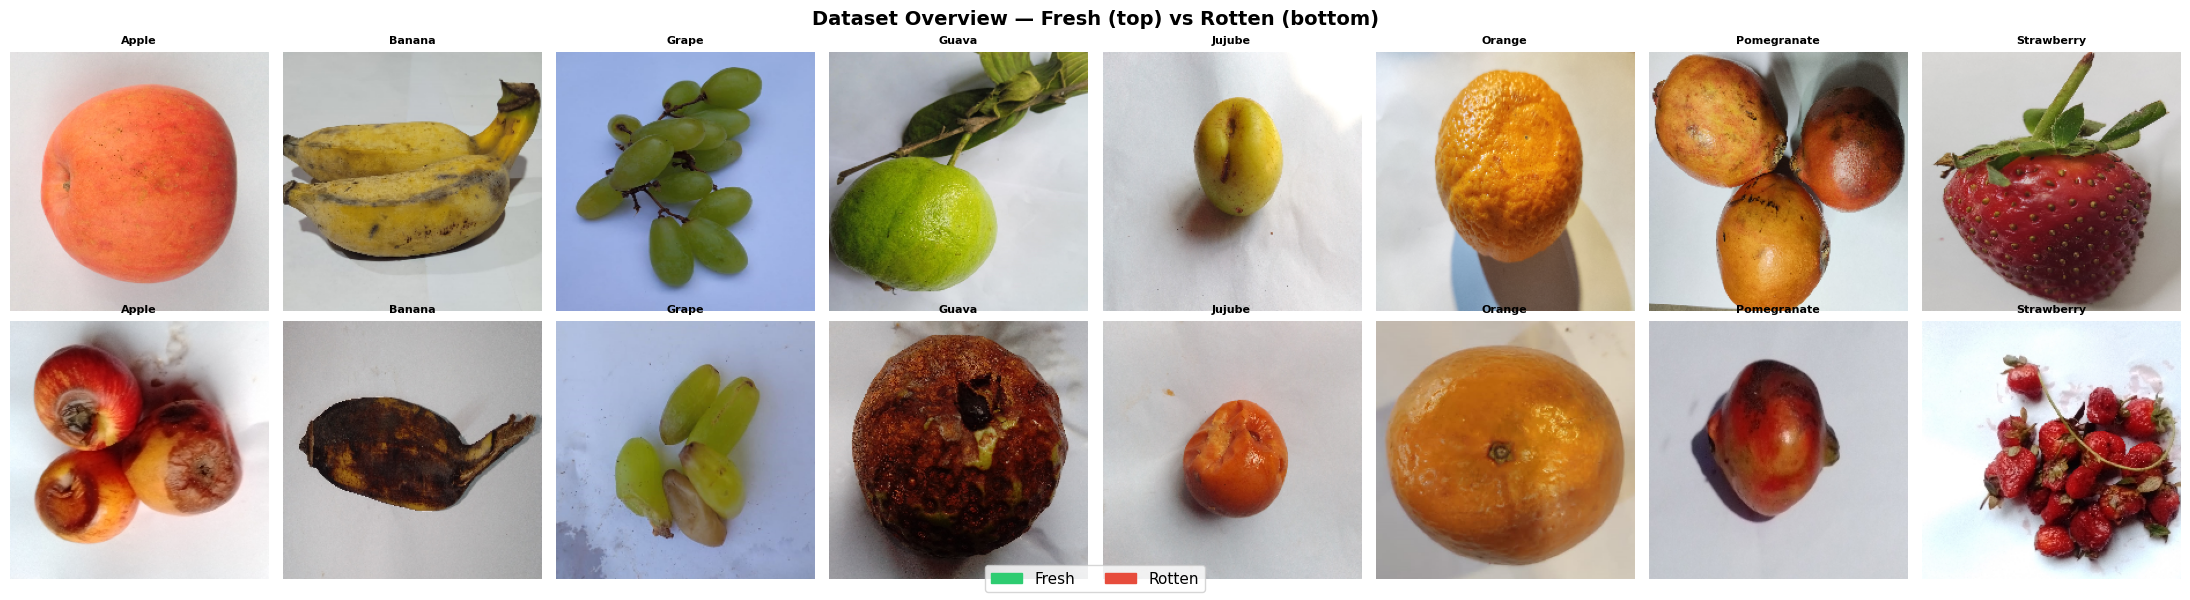

Saved: /content/drive/MyDrive/freshness_results_fixed/01_dataset_grid.png
Cell 2 complete


In [ ]:
# ── Load all 7 models ────────────────────────────────────────────
print('='*62)
print('  LOADING MODELS')
print('='*62)
models = {}
for fname in sorted(os.listdir(MODEL_DIR)):
    if not fname.endswith('.keras'): continue
    try:
        m = load_model(os.path.join(MODEL_DIR, fname), compile=False)
        models[fname] = m
        t = 'MULTICLASS' if fname in MULTICLASS_MODELS else 'BINARY    '
        print(f'  [{t}]  {fname:<40}  params={m.count_params():,}')
    except Exception as e:
        print(f'  FAILED: {fname} -> {e}')

mc_models     = {k: v for k, v in models.items() if k in MULTICLASS_MODELS}
bin_models    = {k: v for k, v in models.items() if k in BINARY_MODELS}
PRIMARY_KEY   = 'MobileNet_16_Finetuned.keras'
primary_model = models[PRIMARY_KEY]
print(f'\n  Loaded {len(models)}/7   Primary: {PRIMARY_KEY}')

# ── Dataset generators ────────────────────────────────────────────
test_datagen = ImageDataGenerator(rescale=1./255)
mc_gen = test_datagen.flow_from_directory(
    LOCAL_TEST_PATH, target_size=IMG_SIZE,
    batch_size=1, class_mode='categorical', shuffle=True)
class_names    = list(mc_gen.class_indices.keys())
fresh_classes  = sorted([c for c in class_names if 'Fresh'  in c])
rotten_classes = sorted([c for c in class_names if 'Rotten' in c])
all_classes    = fresh_classes + rotten_classes
print(f'  Classes: {class_names}')

# ── Evaluate binary models on full 640 test images ────────────────
print('\n' + '='*62)
print('  BINARY MODEL EVALUATION (all 640 images)')
print('='*62)
mc_gen_full = test_datagen.flow_from_directory(
    LOCAL_TEST_PATH, target_size=IMG_SIZE,
    batch_size=32, class_mode='categorical', shuffle=False)
all_imgs_bin, all_true_bin = [], []
mc_gen_full.reset()
for imgs, lbls in mc_gen_full:
    for img, lbl in zip(imgs, lbls):
        all_imgs_bin.append(img)
        idx = int(np.argmax(lbl))
        all_true_bin.append(0 if 'Fresh' in class_names[idx] else 1)
    if len(all_imgs_bin) >= mc_gen.n: break
all_imgs_bin = np.array(all_imgs_bin)

binary_results = {}
for mname, mobj in bin_models.items():
    try:
        raw = mobj.predict(all_imgs_bin, verbose=0, batch_size=32)
        preds_bin = [int(p[0] > 0.5) if raw.shape[-1] == 1
                     else int(np.argmax(p)) for p in raw]
        acc = sum(p == t for p, t in zip(preds_bin, all_true_bin)) / len(all_true_bin)
        binary_results[mname] = acc
        print(f'  {mname:<42}  {acc:.2%}')
    except Exception as e:
        print(f'  FAILED {mname}: {e}')
        binary_results[mname] = None

# ── Dataset sample grid ───────────────────────────────────────────
def read_first_image(cls_name):
    d  = os.path.join(LOCAL_TEST_PATH, cls_name)
    fs = [f for f in os.listdir(d) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    if not fs: return None
    img = cv2.imread(os.path.join(d, fs[0]))
    return cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), IMG_SIZE)

fig, axes = plt.subplots(2, 8, figsize=(22, 6))
fig.suptitle('Dataset Overview — Fresh (top) vs Rotten (bottom)',
             fontsize=14, fontweight='bold')
for i, (row_cls, color) in enumerate(
        [(fresh_classes, '#2ecc71'), (rotten_classes, '#e74c3c')]):
    for j, cls in enumerate(row_cls):
        ax  = axes[i][j]
        img = read_first_image(cls)
        if img is not None: ax.imshow(img)
        ax.set_title(cls.replace('Fresh','').replace('Rotten',''),
                     fontsize=8, fontweight='bold')
        for sp in ax.spines.values():
            sp.set_edgecolor(color); sp.set_linewidth(3)
        ax.axis('off')
handles = [mpatches.Patch(color='#2ecc71', label='Fresh'),
           mpatches.Patch(color='#e74c3c', label='Rotten')]
fig.legend(handles=handles, loc='lower center', ncol=2, fontsize=11)
plt.tight_layout()
p = os.path.join(SAVE_DIR, '01_dataset_grid.png')
plt.savefig(p, dpi=150, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')
print('Cell 2 complete')


TensorFlow: 2.19.0
GPU: /physical_device:GPU:0
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted
Dense layer patched
Results will be saved to: /content/drive/MyDrive/freshness_results_fixed
Dataset already at /content/test
  Class                        Images
  ------------------------------------
  Fresh   FreshApple                  40
  Fresh   FreshBanana                 40
  Fresh   FreshGrape                  40
  Fresh   FreshGuava                  40
  Fresh   FreshJujube                 40
  Fresh   FreshOrange                 40
  Fresh   FreshPomegranate            40
  Fresh   FreshStrawberry             40
  Rotten  RottenApple                 40
  Rotten  RottenBanana                40
  Rotten  RottenGrape                 40
  Rotten  RottenGuava                 40
  Rotten  RottenJujube                40
  Rotten  RottenOrange                40
  Rotten  RottenPomegranate      

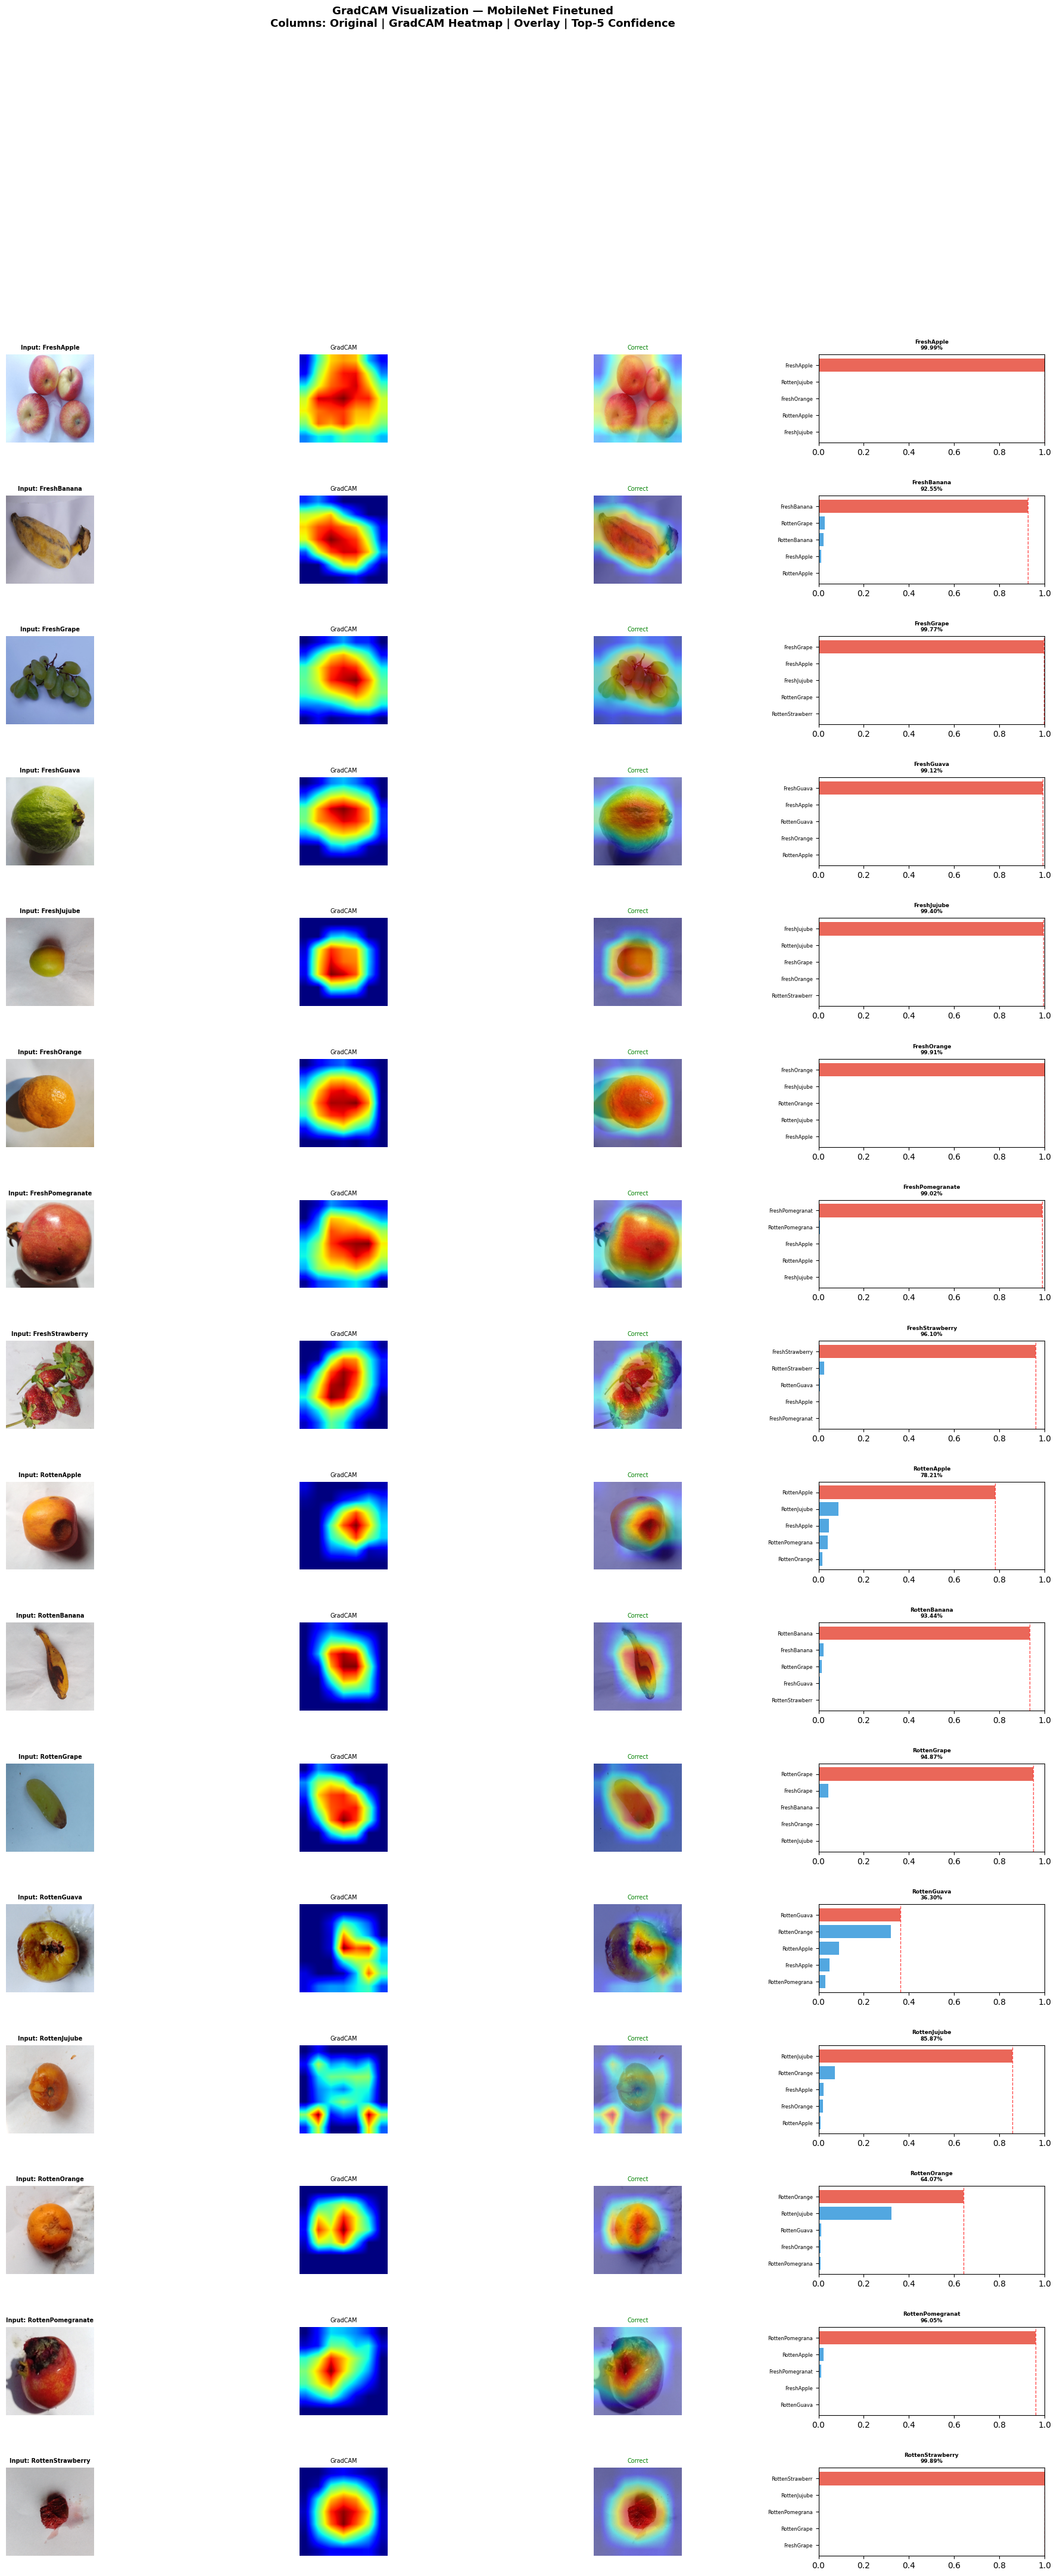

Saved: /content/drive/MyDrive/freshness_results_fixed/02_gradcam_16_classes.png
Cell 3 complete


In [ ]:
import os, json, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import cv2
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense
from collections import Counter
warnings.filterwarnings('ignore')

print('TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print('GPU:', gpus[0].name)
else:
    print('WARNING: No GPU — go Runtime > Change runtime type > T4 GPU > Save')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)
print('Drive mounted')

# Patch Dense layer for Keras version compatibility
_orig_dense_cfg = Dense.from_config.__func__
@classmethod
def _patched_dense_cfg(cls, config):
    config.pop('quantization_config', None)
    return _orig_dense_cfg(cls, config)
Dense.from_config = _patched_dense_cfg
print('Dense layer patched')

# ── Config ────────────────────────
MODEL_DIR       = '/content/drive/MyDrive/freshness_runtime_models'
DRIVE_TEST_PATH = '/content/drive/MyDrive/Mendeley_16Class_Dataset/test'
LOCAL_TEST_PATH = '/content/test'
SAVE_DIR        = '/content/drive/MyDrive/freshness_results_fixed'
IMG_SIZE        = (224, 224)
GRADCAM_LAYER   = 'Conv_1'
DRS_PER_CLASS   = 10   # 10 images x 8 fresh classes = 80 total
FEAT_PER_CLASS  = 10   # 10 images x 16 classes = 160 total

MULTICLASS_MODELS = [
    'MobileNet_16_Frozen.keras',
    'MobileNet_16_Finetuned.keras',
    'Fusion_Model.keras',
]
BINARY_MODELS = [
    'BaseCNN_Original.keras',
    'BaseCNN_Augmented.keras',
    'ResNet_Binary.keras',
    'MobileNet_Binary..keras',
]
os.makedirs(SAVE_DIR, exist_ok=True)
print(f'Results will be saved to: {SAVE_DIR}')

# ── Copy dataset to local storage ─────────────────────
if os.path.exists(LOCAL_TEST_PATH) and len(os.listdir(LOCAL_TEST_PATH)) > 0:
    print('Dataset already at /content/test')
else:
    print('Copying dataset from Drive...')
    shutil.copytree(DRIVE_TEST_PATH, LOCAL_TEST_PATH)
    print('Copy done')

# ── Verify ─────────────────────────────
class_dirs = sorted([d for d in os.listdir(LOCAL_TEST_PATH)
                     if os.path.isdir(os.path.join(LOCAL_TEST_PATH, d))])
total = 0
print(f'  {"Class":<26} {"Images":>8}')
print('  ' + '-'*36)
for c in class_dirs:
    n = len([f for f in os.listdir(os.path.join(LOCAL_TEST_PATH, c))
             if f.lower().endswith(('.jpg','.jpeg','.png'))])
    total += n
    tag = 'Fresh ' if 'Fresh' in c else 'Rotten'
    print(f'  {tag}  {c:<22}  {n:>6}')
print('  ' + '-'*36)
print(f'  {"TOTAL":<26} {total:>8}')
assert len(class_dirs) == 16, f'Expected 16 classes, found {len(class_dirs)}'
print('Cell 1 complete')


# ================================================================
# CELL 3 — Prediction + GradCAM (original logic, one int() fix)
# ================================================================

def prepare_image(img_bgr):
    img_rgb     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, IMG_SIZE)
    arr = img_resized.astype('float32') / 255.0
    arr = np.expand_dims(arr, axis=0)
    return arr, img_resized

def make_gradcam_heatmap(img_array, model, layer_name=GRADCAM_LAYER):
    # Find layer — fallback to last Conv2D if Conv_1 missing
    layer_names = [l.name for l in model.layers]
    if layer_name not in layer_names:
        for layer in reversed(model.layers):
            if isinstance(layer, tf.keras.layers.Conv2D):
                layer_name = layer.name
                break

    grad_model = tf.keras.models.Model(
        inputs  = model.inputs,
        outputs = [model.get_layer(layer_name).output, model.output]
    )
    img_casted = tf.cast(img_array, model.inputs[0].dtype)

    with tf.GradientTape() as tape:
        # grad_model returns a list of its outputs: [conv_out_tensor, model_output_tensor]
        # In case model.output itself is a list of tensors (e.g., multi-output model),
        # the second element of grad_model's output will be that list.
        # So we explicitly extract the desired prediction tensor.
        all_outputs = grad_model(img_casted)
        conv_out = all_outputs[0]

        # The actual model prediction tensor is the second element.
        # Ensure preds_tensor is a single tf.Tensor, not a list of tensors or nested lists.
        preds_tensor = all_outputs[1]
        # Recursively unwrap lists/tuples until a tf.Tensor is found or no more unwrapping is possible
        while isinstance(preds_tensor, (list, tuple)):
            if not preds_tensor: # Handle empty lists/tuples
                raise ValueError("Empty list/tuple encountered in model output for GradCAM.")
            preds_tensor = preds_tensor[0]
            if isinstance(preds_tensor, tf.Tensor): # Found the tensor
                break

        # After unwrapping, if preds_tensor is still not a tf.Tensor, something is wrong.
        if not isinstance(preds_tensor, tf.Tensor):
            raise TypeError(f"Model output could not be resolved to a single tf.Tensor. Got type: {type(preds_tensor)}")

        # Use tf.math.top_k to robustly get the single predicted index
        # preds_tensor is (batch_size, num_classes). Since batch_size is 1, preds_tensor[0] is (num_classes,)
        _, indices = tf.math.top_k(preds_tensor[0], k=1)
        pred_idx = indices.numpy().item()

        # Loss is calculated on the main prediction tensor for the chosen class
        loss = preds_tensor[:, pred_idx]

    grads  = tape.gradient(loss, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    hm     = conv_out[0] @ pooled[..., tf.newaxis]
    hm     = tf.squeeze(hm).numpy()
    hm     = np.maximum(hm, 0)
    if hm.max() > 0: hm /= hm.max()
    hm     = cv2.resize(hm, IMG_SIZE)
    return hm, preds_tensor.numpy()[0], pred_idx

def overlay_heatmap(img_rgb, hm, alpha=0.45):
    jet = cv2.applyColorMap(np.uint8(255 * hm), cv2.COLORMAP_JET)
    jet = cv2.cvtColor(jet, cv2.COLOR_BGR2RGB)
    return (alpha * jet + (1 - alpha) * img_rgb).astype(np.uint8)

# ── Run for all 16 classes ──────────────────────────
print('='*65)
print('  PREDICTION + GradCAM — MobileNet Finetuned')
print('  One image per class x 16 classes')
print('='*65)

all_predictions = []
all_confidences = []

for cls_name in all_classes:
    cls_dir = os.path.join(LOCAL_TEST_PATH, cls_name)
    files   = sorted([f for f in os.listdir(cls_dir)
                      if f.lower().endswith(('.jpg','.jpeg','.png'))])
    if not files: continue

    img_bgr            = cv2.imread(os.path.join(cls_dir, files[0]))
    img_array, img_rgb = prepare_image(img_bgr)
    heatmap, preds, pidx = make_gradcam_heatmap(img_array, primary_model)
    pred_class = class_names[pidx]
    confidence = float(preds[pidx])
    correct    = (pred_class == cls_name)

    all_predictions.append({
        'class': cls_name, 'pred': pred_class,
        'confidence': confidence, 'correct': correct,
        'heatmap': heatmap, 'img_rgb': img_rgb, 'preds': preds
    })
    all_confidences.append(confidence)
    print(f"  {'OK' if correct else 'XX'}  {cls_name:<26} ->  "
          f"{pred_class:<26}  {confidence:.2%}")

# Mean confidence across all 16 (used in ECS — not just first image)
MEAN_CONFIDENCE = float(np.mean(all_confidences))
demo_acc = sum(e['correct'] for e in all_predictions) / len(all_predictions)
print(f'\n  Demo accuracy   : {demo_acc:.2%}  (1 img/class — use Exp4 for real accuracy)')
print(f'  Mean confidence : {MEAN_CONFIDENCE:.3f}')

# ── GradCAM figure ───────────────────────────────
nrows = len(all_predictions)
fig   = plt.figure(figsize=(24, nrows * 3.0))
fig.suptitle(
    'GradCAM Visualization — MobileNet Finetuned\n'
    'Columns: Original | GradCAM Heatmap | Overlay | Top-5 Confidence',
    fontsize=13, fontweight='bold', y=1.002)
gs = gridspec.GridSpec(nrows, 4, figure=fig, hspace=0.6, wspace=0.3)

for row_i, entry in enumerate(all_predictions):
    bc = '#2ecc71' if 'Fresh' in entry['class'] else '#e74c3c'
    ax0 = fig.add_subplot(gs[row_i, 0])
    ax0.imshow(entry['img_rgb'])
    ax0.set_title(f"Input: {entry['class']}", fontsize=7, fontweight='bold')
    for sp in ax0.spines.values(): sp.set_edgecolor(bc); sp.set_linewidth(2.5)
    ax0.axis('off')

    ax1 = fig.add_subplot(gs[row_i, 1])
    ax1.imshow(entry['heatmap'], cmap='jet', vmin=0, vmax=1)
    ax1.set_title('GradCAM', fontsize=7); ax1.axis('off')

    ax2 = fig.add_subplot(gs[row_i, 2])
    ax2.imshow(overlay_heatmap(entry['img_rgb'], entry['heatmap']))
    lbl = 'Correct' if entry['correct'] else 'WRONG'
    ax2.set_title(lbl, fontsize=7,
                  color='green' if entry['correct'] else 'red')
    ax2.axis('off')

    ax3    = fig.add_subplot(gs[row_i, 3])
    pidx_e = class_names.index(entry['pred'])
    t5i    = np.argsort(entry['preds'])[::-1][:5]
    clrs   = ['#e74c3c' if i == pidx_e else '#3498db' for i in t5i]
    ax3.barh(range(5), entry['preds'][t5i][::-1], color=clrs[::-1], alpha=0.85)
    ax3.set_yticks(range(5))
    ax3.set_yticklabels([class_names[i][:15] for i in t5i[::-1]], fontsize=6)
    ax3.set_xlim(0, 1)
    ax3.set_title(f"{entry['pred'][:16]}\n{entry['confidence']:.2%}",
                  fontsize=6.5, fontweight='bold')
    ax3.axvline(entry['confidence'], color='red', ls='--', lw=1, alpha=0.7)

p3 = os.path.join(SAVE_DIR, '02_gradcam_16_classes.png')
plt.savefig(p3, dpi=150, bbox_inches='tight'); plt.show()
print(f'Saved: {p3}')
print('Cell 3 complete')


EXP 1 — Dataset Reliability Score
  10 images/class x 8 fresh classes = 80 total
  FreshApple                  mean=0.772  std=0.033  good
  FreshBanana                 mean=0.669  std=0.083  moderate
  FreshGrape                  mean=0.595  std=0.080  moderate
  FreshGuava                  mean=0.788  std=0.058  good
  FreshJujube                 mean=0.545  std=0.064  moderate
  FreshOrange                 mean=0.643  std=0.064  moderate
  FreshPomegranate            mean=0.826  std=0.021  good
  FreshStrawberry             mean=0.732  std=0.064  good

  Mean DRS = 0.696  (std=0.093)
  69.6% of model attention is on the fruit


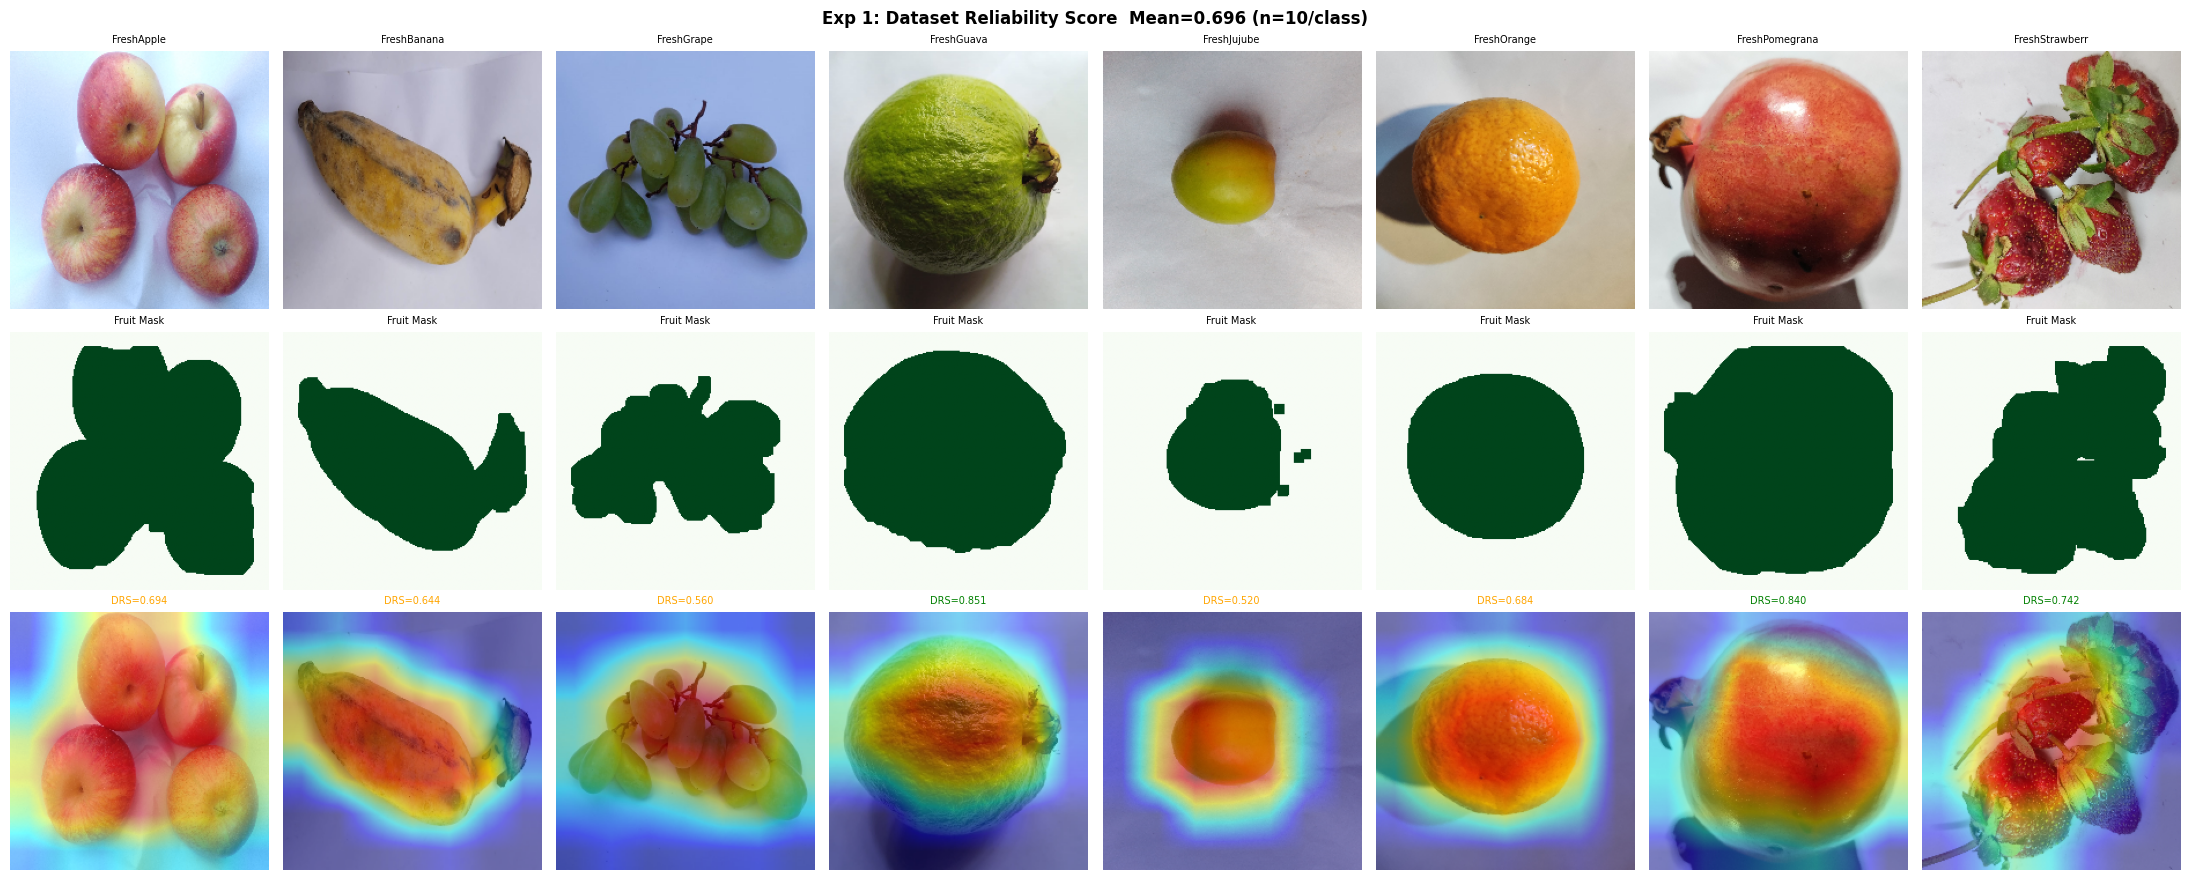

Saved: /content/drive/MyDrive/freshness_results_fixed/03_exp1_drs.png

EXP 2 — GradCAM Stability  (all 16 classes, fresh + rotten)
  F  FreshApple                  noise=0.921  bright=0.975  stab=0.948
  F  FreshBanana                 noise=0.915  bright=0.979  stab=0.947
  F  FreshGrape                  noise=0.982  bright=0.999  stab=0.990
  F  FreshGuava                  noise=0.891  bright=0.998  stab=0.944
  F  FreshJujube                 noise=0.891  bright=0.997  stab=0.944
  F  FreshOrange                 noise=0.875  bright=0.996  stab=0.936
  F  FreshPomegranate            noise=0.969  bright=0.994  stab=0.982
  F  FreshStrawberry             noise=0.778  bright=0.981  stab=0.879
  R  RottenApple                 noise=0.923  bright=0.896  stab=0.910
  R  RottenBanana                noise=0.813  bright=0.969  stab=0.891
  R  RottenGrape                 noise=-0.425  bright=0.997  stab=0.286
  R  RottenGuava                 noise=0.697  bright=0.908  stab=0.802
  R  RottenJujub

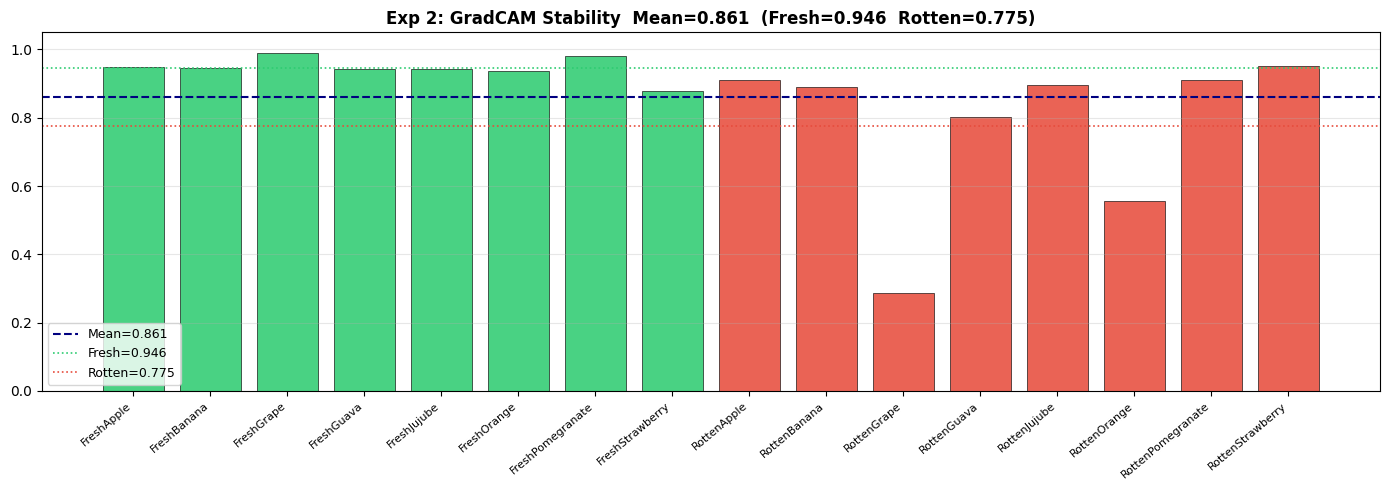

Saved: /content/drive/MyDrive/freshness_results_fixed/04_exp2_stability.png

EXP 3 — Feature Analysis  (all 16 classes, entropy concentration)
  F  FreshApple                  edge=0.680  color=0.621  conc=0.021
  F  FreshBanana                 edge=0.639  color=0.592  conc=0.031
  F  FreshGrape                  edge=0.676  color=0.628  conc=0.020
  F  FreshGuava                  edge=0.598  color=0.587  conc=0.037
  F  FreshJujube                 edge=0.781  color=0.341  conc=0.064
  F  FreshOrange                 edge=0.721  color=0.544  conc=0.034
  F  FreshPomegranate            edge=0.541  color=0.547  conc=0.023
  F  FreshStrawberry             edge=0.549  color=0.537  conc=0.025
  R  RottenApple                 edge=0.430  color=0.360  conc=0.054
  R  RottenBanana                edge=0.656  color=0.486  conc=0.044
  R  RottenGrape                 edge=0.655  color=0.555  conc=0.034
  R  RottenGuava                 edge=0.564  color=0.533  conc=0.029
  R  RottenJujube            

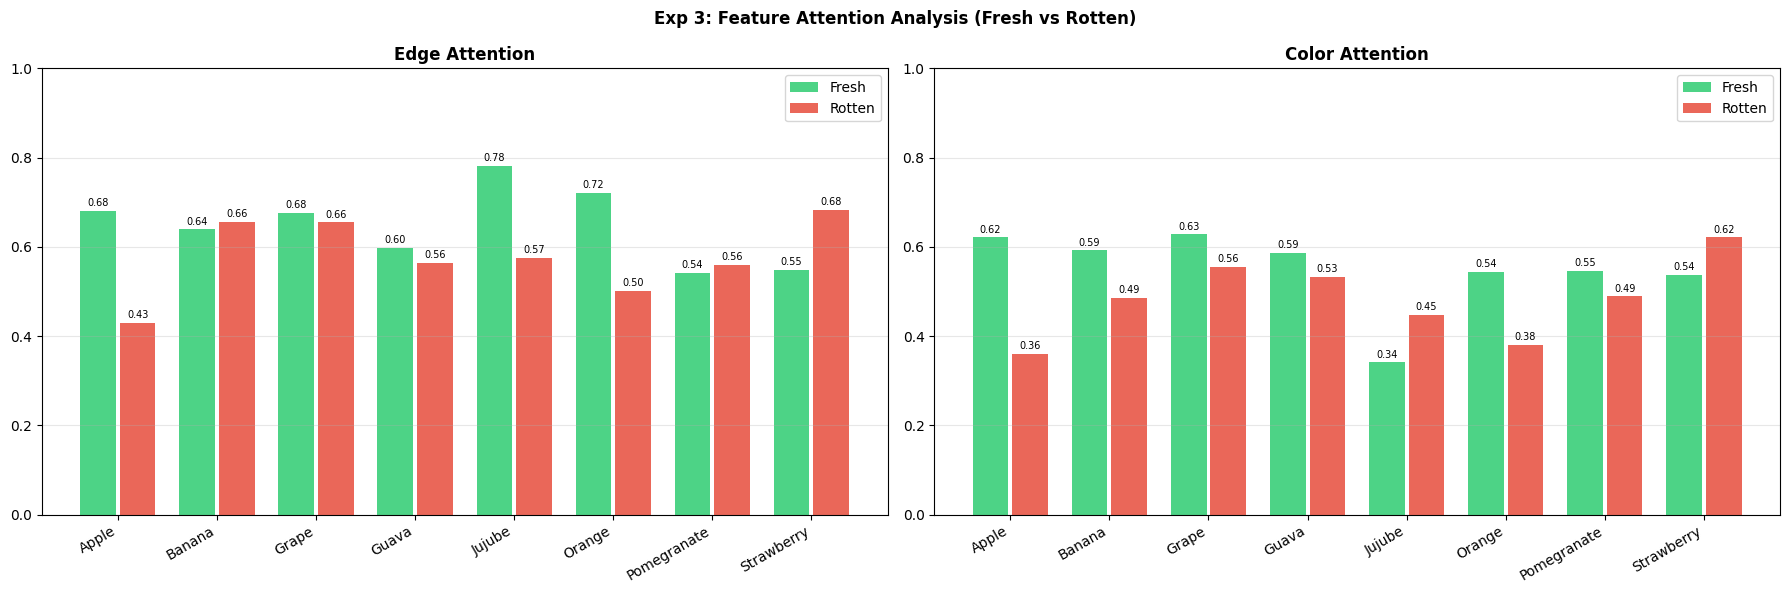

Saved: /content/drive/MyDrive/freshness_results_fixed/05_exp3_features.png

EXP 4 — Hybrid System  (all 640 samples, both strategies)
Found 640 images belonging to 16 classes.

  Evaluated on: 640 samples
  Fusion_Model.keras                          97.81%
  MobileNet_16_Finetuned.keras                97.66%
  MobileNet_16_Frozen.keras                   97.81%
  Hybrid Confidence    : 98.28%
  Hybrid Majority Vote : 98.44%
  Best single model    : 97.81%
  Best hybrid strategy : Majority Vote (98.44%)
  Majority agreement   : 100.00%


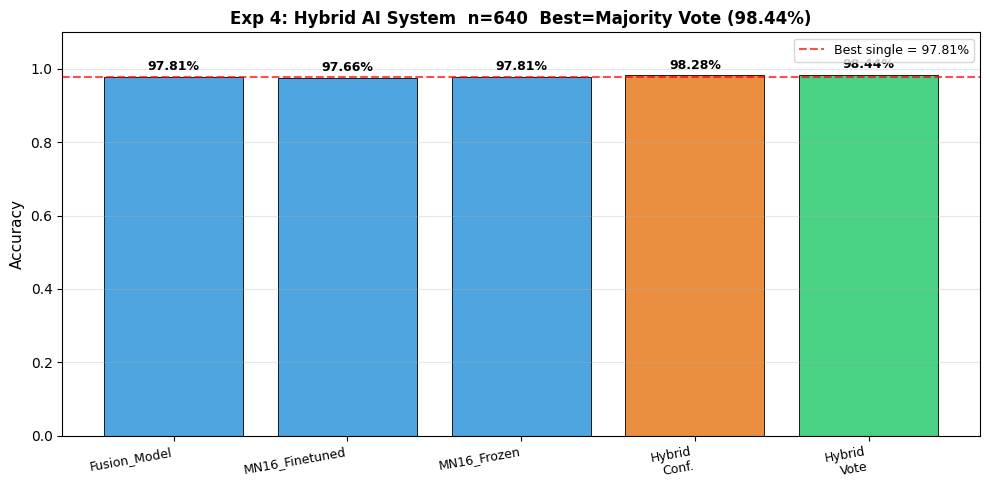

Saved: /content/drive/MyDrive/freshness_results_fixed/06_exp4_hybrid.png
Cell 4 complete


In [ ]:
# ================================================================
# CELL 4 — Four Novel Experiments (all fixed)
# ================================================================

# ── EXP 1: Dataset Reliability Score ─────────────────────────────
# FIX: 10 images per class x 8 fresh classes = 80 total (was 8)
print('='*62)
print(f'EXP 1 — Dataset Reliability Score')
print(f'  {DRS_PER_CLASS} images/class x 8 fresh classes = {DRS_PER_CLASS*8} total')
print('='*62)

def grabcut_mask(img_rgb):
    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    mask    = np.zeros(img_bgr.shape[:2], np.uint8)
    h, w    = img_bgr.shape[:2]
    margin  = max(10, int(min(h, w) * 0.08))
    rect    = (margin, margin, w - 2*margin, h - 2*margin)
    bgd     = np.zeros((1, 65), np.float64)
    fgd     = np.zeros((1, 65), np.float64)
    try:
        cv2.grabCut(img_bgr, mask, rect, bgd, fgd, 5, cv2.GC_INIT_WITH_RECT)
        fm = np.where((mask == 2)|(mask == 0), 0, 1).astype(np.float32)
        fm = cv2.dilate(fm, np.ones((5,5), np.uint8), iterations=2)
    except Exception:
        fm = np.ones(img_bgr.shape[:2], np.float32)
    return fm

def compute_drs(hm, mask):
    return float((hm * mask).sum() / (hm.sum() + 1e-8))

drs_per_class = {}
drs_visuals   = []

for cls_name in fresh_classes:
    cls_dir = os.path.join(LOCAL_TEST_PATH, cls_name)
    files   = sorted([f for f in os.listdir(cls_dir)
                      if f.lower().endswith(('.jpg','.jpeg','.png'))])[:DRS_PER_CLASS]
    scores  = []
    first   = True
    for fname in files:
        bgr        = cv2.imread(os.path.join(cls_dir, fname))
        arr, rgb_d = prepare_image(bgr)
        hm, _, _   = make_gradcam_heatmap(arr, primary_model)
        mask       = grabcut_mask(rgb_d)
        scores.append(compute_drs(hm, mask))
        if first:
            drs_visuals.append((cls_name, rgb_d, hm, mask, scores[-1]))
            first = False
    mn = float(np.mean(scores))
    sd = float(np.std(scores))
    drs_per_class[cls_name] = {'mean': mn, 'std': sd}
    print(f'  {cls_name:<26}  mean={mn:.3f}  std={sd:.3f}  '
          f'{"good" if mn > 0.7 else "moderate"}')

mean_drs = float(np.mean([v['mean'] for v in drs_per_class.values()]))
std_drs  = float(np.std( [v['mean'] for v in drs_per_class.values()]))
print(f'\n  Mean DRS = {mean_drs:.3f}  (std={std_drs:.3f})')
print(f'  {mean_drs*100:.1f}% of model attention is on the fruit')

fig, axes = plt.subplots(3, 8, figsize=(22, 9))
fig.suptitle(f'Exp 1: Dataset Reliability Score  Mean={mean_drs:.3f} '
             f'(n={DRS_PER_CLASS}/class)',
             fontsize=12, fontweight='bold')
for col, (cls, img, hm, mk, sc) in enumerate(drs_visuals):
    axes[0][col].imshow(img)
    axes[0][col].set_title(cls[:14], fontsize=7); axes[0][col].axis('off')
    axes[1][col].imshow(mk, cmap='Greens')
    axes[1][col].set_title('Fruit Mask', fontsize=7); axes[1][col].axis('off')
    axes[2][col].imshow(overlay_heatmap(img, hm))
    axes[2][col].set_title(f'DRS={sc:.3f}', fontsize=7,
                           color='green' if sc > 0.7 else 'orange')
    axes[2][col].axis('off')
plt.tight_layout()
p_e1 = os.path.join(SAVE_DIR, '03_exp1_drs.png')
plt.savefig(p_e1, dpi=150, bbox_inches='tight'); plt.show()
print(f'Saved: {p_e1}')


# ── EXP 2: GradCAM Stability ──────────────────────────────────────
# FIX: all 16 classes including rotten (was 6 fresh only)
print('\n' + '='*62)
print('EXP 2 — GradCAM Stability  (all 16 classes, fresh + rotten)')
print('='*62)

def add_noise(arr, std=0.05):
    return np.clip(arr + np.random.normal(0, std, arr.shape).astype('float32'), 0, 1)

def add_brightness(arr, factor=1.3):
    return np.clip(arr * factor, 0, 1)

def pearson(h1, h2):
    r = np.corrcoef(h1.flatten(), h2.flatten())[0, 1]
    return float(np.nan_to_num(r))

stab_rows = []
for entry in all_predictions:   # all 16
    base = entry['img_rgb'].astype('float32') / 255.0
    orig = np.expand_dims(base, 0)
    hm_o, _, _ = make_gradcam_heatmap(orig, primary_model)
    hm_n, _, _ = make_gradcam_heatmap(add_noise(orig), primary_model)
    hm_b, _, _ = make_gradcam_heatmap(add_brightness(orig), primary_model)
    rn  = pearson(hm_o, hm_n)
    rb  = pearson(hm_o, hm_b)
    ms  = (rn + rb) / 2
    ft  = 'Fresh' if 'Fresh' in entry['class'] else 'Rotten'
    stab_rows.append({'Class': entry['class'], 'Type': ft,
                      'Noise': round(rn,3), 'Bright': round(rb,3),
                      'Stability': round(ms,3)})
    print(f"  {'F' if ft=='Fresh' else 'R'}  {entry['class']:<26}  "
          f"noise={rn:.3f}  bright={rb:.3f}  stab={ms:.3f}")

stab_df        = pd.DataFrame(stab_rows)
mean_stability = float(stab_df['Stability'].mean())
fresh_stab     = float(stab_df[stab_df['Type']=='Fresh']['Stability'].mean())
rotten_stab    = float(stab_df[stab_df['Type']=='Rotten']['Stability'].mean())
print(f'\n  Mean stability = {mean_stability:.3f}')
print(f'  Fresh classes  = {fresh_stab:.3f}')
print(f'  Rotten classes = {rotten_stab:.3f}')
if fresh_stab > rotten_stab:
    print(f'  Fresh more stable by +{fresh_stab-rotten_stab:.3f} (expected — rotten harder for model)')

fig, ax = plt.subplots(figsize=(14, 5))
colors_s = ['#2ecc71' if t == 'Fresh' else '#e74c3c' for t in stab_df['Type']]
ax.bar(range(len(stab_df)), stab_df['Stability'],
       color=colors_s, alpha=0.87, edgecolor='black', lw=0.5)
ax.axhline(mean_stability, color='navy', ls='--', lw=1.5,
           label=f'Mean={mean_stability:.3f}')
ax.axhline(fresh_stab,  color='#2ecc71', ls=':', lw=1.2,
           label=f'Fresh={fresh_stab:.3f}')
ax.axhline(rotten_stab, color='#e74c3c', ls=':', lw=1.2,
           label=f'Rotten={rotten_stab:.3f}')
ax.set_xticks(range(len(stab_df)))
ax.set_xticklabels(stab_df['Class'], rotation=40, ha='right', fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_title(f'Exp 2: GradCAM Stability  Mean={mean_stability:.3f}  '
             f'(Fresh={fresh_stab:.3f}  Rotten={rotten_stab:.3f})',
             fontweight='bold')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
p_e2 = os.path.join(SAVE_DIR, '04_exp2_stability.png')
plt.savefig(p_e2, dpi=150, bbox_inches='tight'); plt.show()
print(f'Saved: {p_e2}')


# ── EXP 3: Feature Analysis ───────────────────────────────────────
# FIX 1: fresh + rotten (was fresh only)
# FIX 2: entropy concentration (was broken percentile = always 0.250)
print('\n' + '='*62)
print('EXP 3 — Feature Analysis  (all 16 classes, entropy concentration)')
print('='*62)

def edge_map(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.Canny(gray, 50, 150).astype(np.float32) / 255.0

def color_map(img_rgb):
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l   = cv2.split(lab)[0]
    var = np.abs(cv2.Laplacian(l, cv2.CV_64F)).astype(np.float32)
    if var.max() > 0: var /= var.max()
    return var

def attn_score(hm, feat):
    return float((hm * feat).sum() / (feat.sum() + 1e-8))

def entropy_concentration(hm):
    # FIX: entropy-based — values now differ between fruits (not always 0.250)
    # High value = model attention focused on small area
    # Low value  = model attention spread across image
    hm_norm = hm / (hm.sum() + 1e-8)
    entropy  = -np.sum(hm_norm * np.log(hm_norm + 1e-8))
    return float(1.0 - (entropy / np.log(hm.size)))

feat_results = []
for cls_name in all_classes:   # all 16 fresh + rotten
    cls_dir = os.path.join(LOCAL_TEST_PATH, cls_name)
    files   = sorted([f for f in os.listdir(cls_dir)
                      if f.lower().endswith(('.jpg','.jpeg','.png'))])[:FEAT_PER_CLASS]
    es, cs, concs = [], [], []
    for fname in files:
        bgr        = cv2.imread(os.path.join(cls_dir, fname))
        arr, rgb_f = prepare_image(bgr)
        hm, _, _   = make_gradcam_heatmap(arr, primary_model)
        es.append(attn_score(hm, edge_map(rgb_f)))
        cs.append(attn_score(hm, color_map(rgb_f)))
        concs.append(entropy_concentration(hm))
    fruit = cls_name.replace('Fresh','').replace('Rotten','')
    ftype = 'Fresh' if 'Fresh' in cls_name else 'Rotten'
    me, mc_v, mconc = np.mean(es), np.mean(cs), np.mean(concs)
    feat_results.append({
        'Class': cls_name, 'Fruit': fruit, 'Type': ftype,
        'Edge':  round(float(me),3),
        'Color': round(float(mc_v),3),
        'Concentration': round(float(mconc),3),
        'Gap':   round(abs(me - mc_v),3),
        'Dominant': 'Edge' if me > mc_v else 'Color'
    })
    print(f"  {'F' if ftype=='Fresh' else 'R'}  {cls_name:<26}  "
          f"edge={me:.3f}  color={mc_v:.3f}  conc={mconc:.3f}")

feat_df = pd.DataFrame(feat_results)
print(f'\n  Concentration range: '
      f'min={feat_df["Concentration"].min():.3f}  '
      f'max={feat_df["Concentration"].max():.3f}')
print('  (Values now differ = entropy fix working)')

# Fresh vs Rotten comparison table
print('\n  Fresh vs Rotten per fruit:')
print(f'  {"Fruit":<14} {"FreshEdge":>10} {"RottenEdge":>11} '
      f'{"FreshColor":>11} {"RottenColor":>12}')
print('  ' + '-'*52)
for fruit in [c.replace('Fresh','') for c in fresh_classes]:
    fr = feat_df[(feat_df['Fruit']==fruit) & (feat_df['Type']=='Fresh')]
    ro = feat_df[(feat_df['Fruit']==fruit) & (feat_df['Type']=='Rotten')]
    if fr.empty or ro.empty: continue
    print(f'  {fruit:<14} {fr["Edge"].values[0]:>10.3f} '
          f'{ro["Edge"].values[0]:>11.3f} '
          f'{fr["Color"].values[0]:>11.3f} '
          f'{ro["Color"].values[0]:>12.3f}')

fruits_list = [c.replace('Fresh','') for c in fresh_classes]
x = np.arange(len(fruits_list)); w = 0.2
fig, axes_f = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Exp 3: Feature Attention Analysis (Fresh vs Rotten)',
             fontsize=12, fontweight='bold')
for ai, (mt, title) in enumerate([('Edge','Edge Attention'),
                                   ('Color','Color Attention')]):
    ax = axes_f[ai]
    fv = [feat_df[(feat_df['Fruit']==f) &
                  (feat_df['Type']=='Fresh')][mt].values[0]
          for f in fruits_list]
    rv = [feat_df[(feat_df['Fruit']==f) &
                  (feat_df['Type']=='Rotten')][mt].values[0]
          for f in fruits_list]
    b1 = ax.bar(x - w, fv, w*1.8, label='Fresh',  color='#2ecc71', alpha=0.85)
    b2 = ax.bar(x + w, rv, w*1.8, label='Rotten', color='#e74c3c', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(fruits_list, rotation=30, ha='right', fontsize=10)
    ax.set_ylim(0, 1); ax.set_title(title, fontweight='bold')
    ax.legend(); ax.grid(axis='y', alpha=0.3)
    for bar in list(b1) + list(b2):
        ax.annotate(f'{bar.get_height():.2f}',
                    (bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0,2), textcoords='offset points',
                    ha='center', va='bottom', fontsize=7)
plt.tight_layout()
p_e3 = os.path.join(SAVE_DIR, '05_exp3_features.png')
plt.savefig(p_e3, dpi=150, bbox_inches='tight'); plt.show()
print(f'Saved: {p_e3}')


# ── EXP 4: Hybrid System ──────────────────────────────────────────
# FIX 1: all 640 samples (was 50)
# FIX 2: majority voting compared alongside confidence-based
print('\n' + '='*62)
print('EXP 4 — Hybrid System  (all 640 samples, both strategies)')
print('='*62)

mc_gen_eval = test_datagen.flow_from_directory(
    LOCAL_TEST_PATH, target_size=IMG_SIZE,
    batch_size=32, class_mode='categorical', shuffle=False)
mc_gen_eval.reset()

per_ok   = {k: 0 for k in mc_models}
conf_ok  = 0; vote_ok = 0; agree = 0; total_eval = 0

for batch_imgs, batch_lbls in mc_gen_eval:
    for img_b, lbl_b in zip(batch_imgs, batch_lbls):
        true_idx = int(np.argmax(lbl_b))
        img_exp  = np.expand_dims(img_b, 0)
        pd_dict  = {}
        for mname, mobj in mc_models.items():
            p_arr  = mobj.predict(img_exp, verbose=0)[0]
            p_idx  = int(np.argmax(p_arr))
            p_conf = float(p_arr[p_idx])
            pd_dict[mname] = {'idx': p_idx, 'conf': p_conf}
            if p_idx == true_idx: per_ok[mname] += 1
        # Strategy A: highest confidence wins
        best = max(pd_dict.items(), key=lambda x: x[1]['conf'])
        if best[1]['idx'] == true_idx: conf_ok += 1
        # Strategy B: majority vote
        votes   = Counter([v['idx'] for v in pd_dict.values()])
        tv, tc  = votes.most_common(1)[0]
        if tc >= 2: agree += 1
        if tv == true_idx: vote_ok += 1
        total_eval += 1
    if total_eval >= mc_gen.n: break

model_accs      = {k: v/total_eval for k, v in per_ok.items()}
hybrid_conf_acc = conf_ok / total_eval
hybrid_vote_acc = vote_ok / total_eval
best_single     = max(model_accs.values())
best_hybrid     = max(hybrid_conf_acc, hybrid_vote_acc)
best_hybrid_name = 'Confidence' if hybrid_conf_acc >= hybrid_vote_acc                    else 'Majority Vote'

print(f'\n  Evaluated on: {total_eval} samples')
for mn, ac in model_accs.items():
    print(f'  {mn:<42}  {ac:.2%}')
print(f'  Hybrid Confidence    : {hybrid_conf_acc:.2%}')
print(f'  Hybrid Majority Vote : {hybrid_vote_acc:.2%}')
print(f'  Best single model    : {best_single:.2%}')
print(f'  Best hybrid strategy : {best_hybrid_name} ({best_hybrid:.2%})')
print(f'  Majority agreement   : {agree/total_eval:.2%}')

bl   = ([n.replace('.keras','').replace('MobileNet_16_','MN16_')
         for n in model_accs]
        + ['Hybrid\nConf.', 'Hybrid\nVote'])
bv   = list(model_accs.values()) + [hybrid_conf_acc, hybrid_vote_acc]
bc2  = ['#3498db'] * len(model_accs) + ['#e67e22', '#2ecc71']
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(bl, bv, color=bc2, alpha=0.87, edgecolor='black', lw=0.7)
ax.axhline(best_single, color='red', ls='--', lw=1.5, alpha=0.7,
           label=f'Best single = {best_single:.2%}')
ax.set_ylim(0, 1.1); ax.set_ylabel('Accuracy', fontsize=11)
ax.set_title(f'Exp 4: Hybrid AI System  n={total_eval}  '
             f'Best={best_hybrid_name} ({best_hybrid:.2%})',
             fontweight='bold')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
            f'{bar.get_height():.2%}',
            ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.xticks(rotation=10, ha='right', fontsize=9)
plt.tight_layout()
p_e4 = os.path.join(SAVE_DIR, '06_exp4_hybrid.png')
plt.savefig(p_e4, dpi=150, bbox_inches='tight'); plt.show()
print(f'Saved: {p_e4}')
print('Cell 4 complete')


ECS Calculation:
  0.4 x DRS(0.696)  +  0.4 x Stability(0.861)  +  0.2 x ConfMean(0.897)
  = 0.802  ->  HIGH


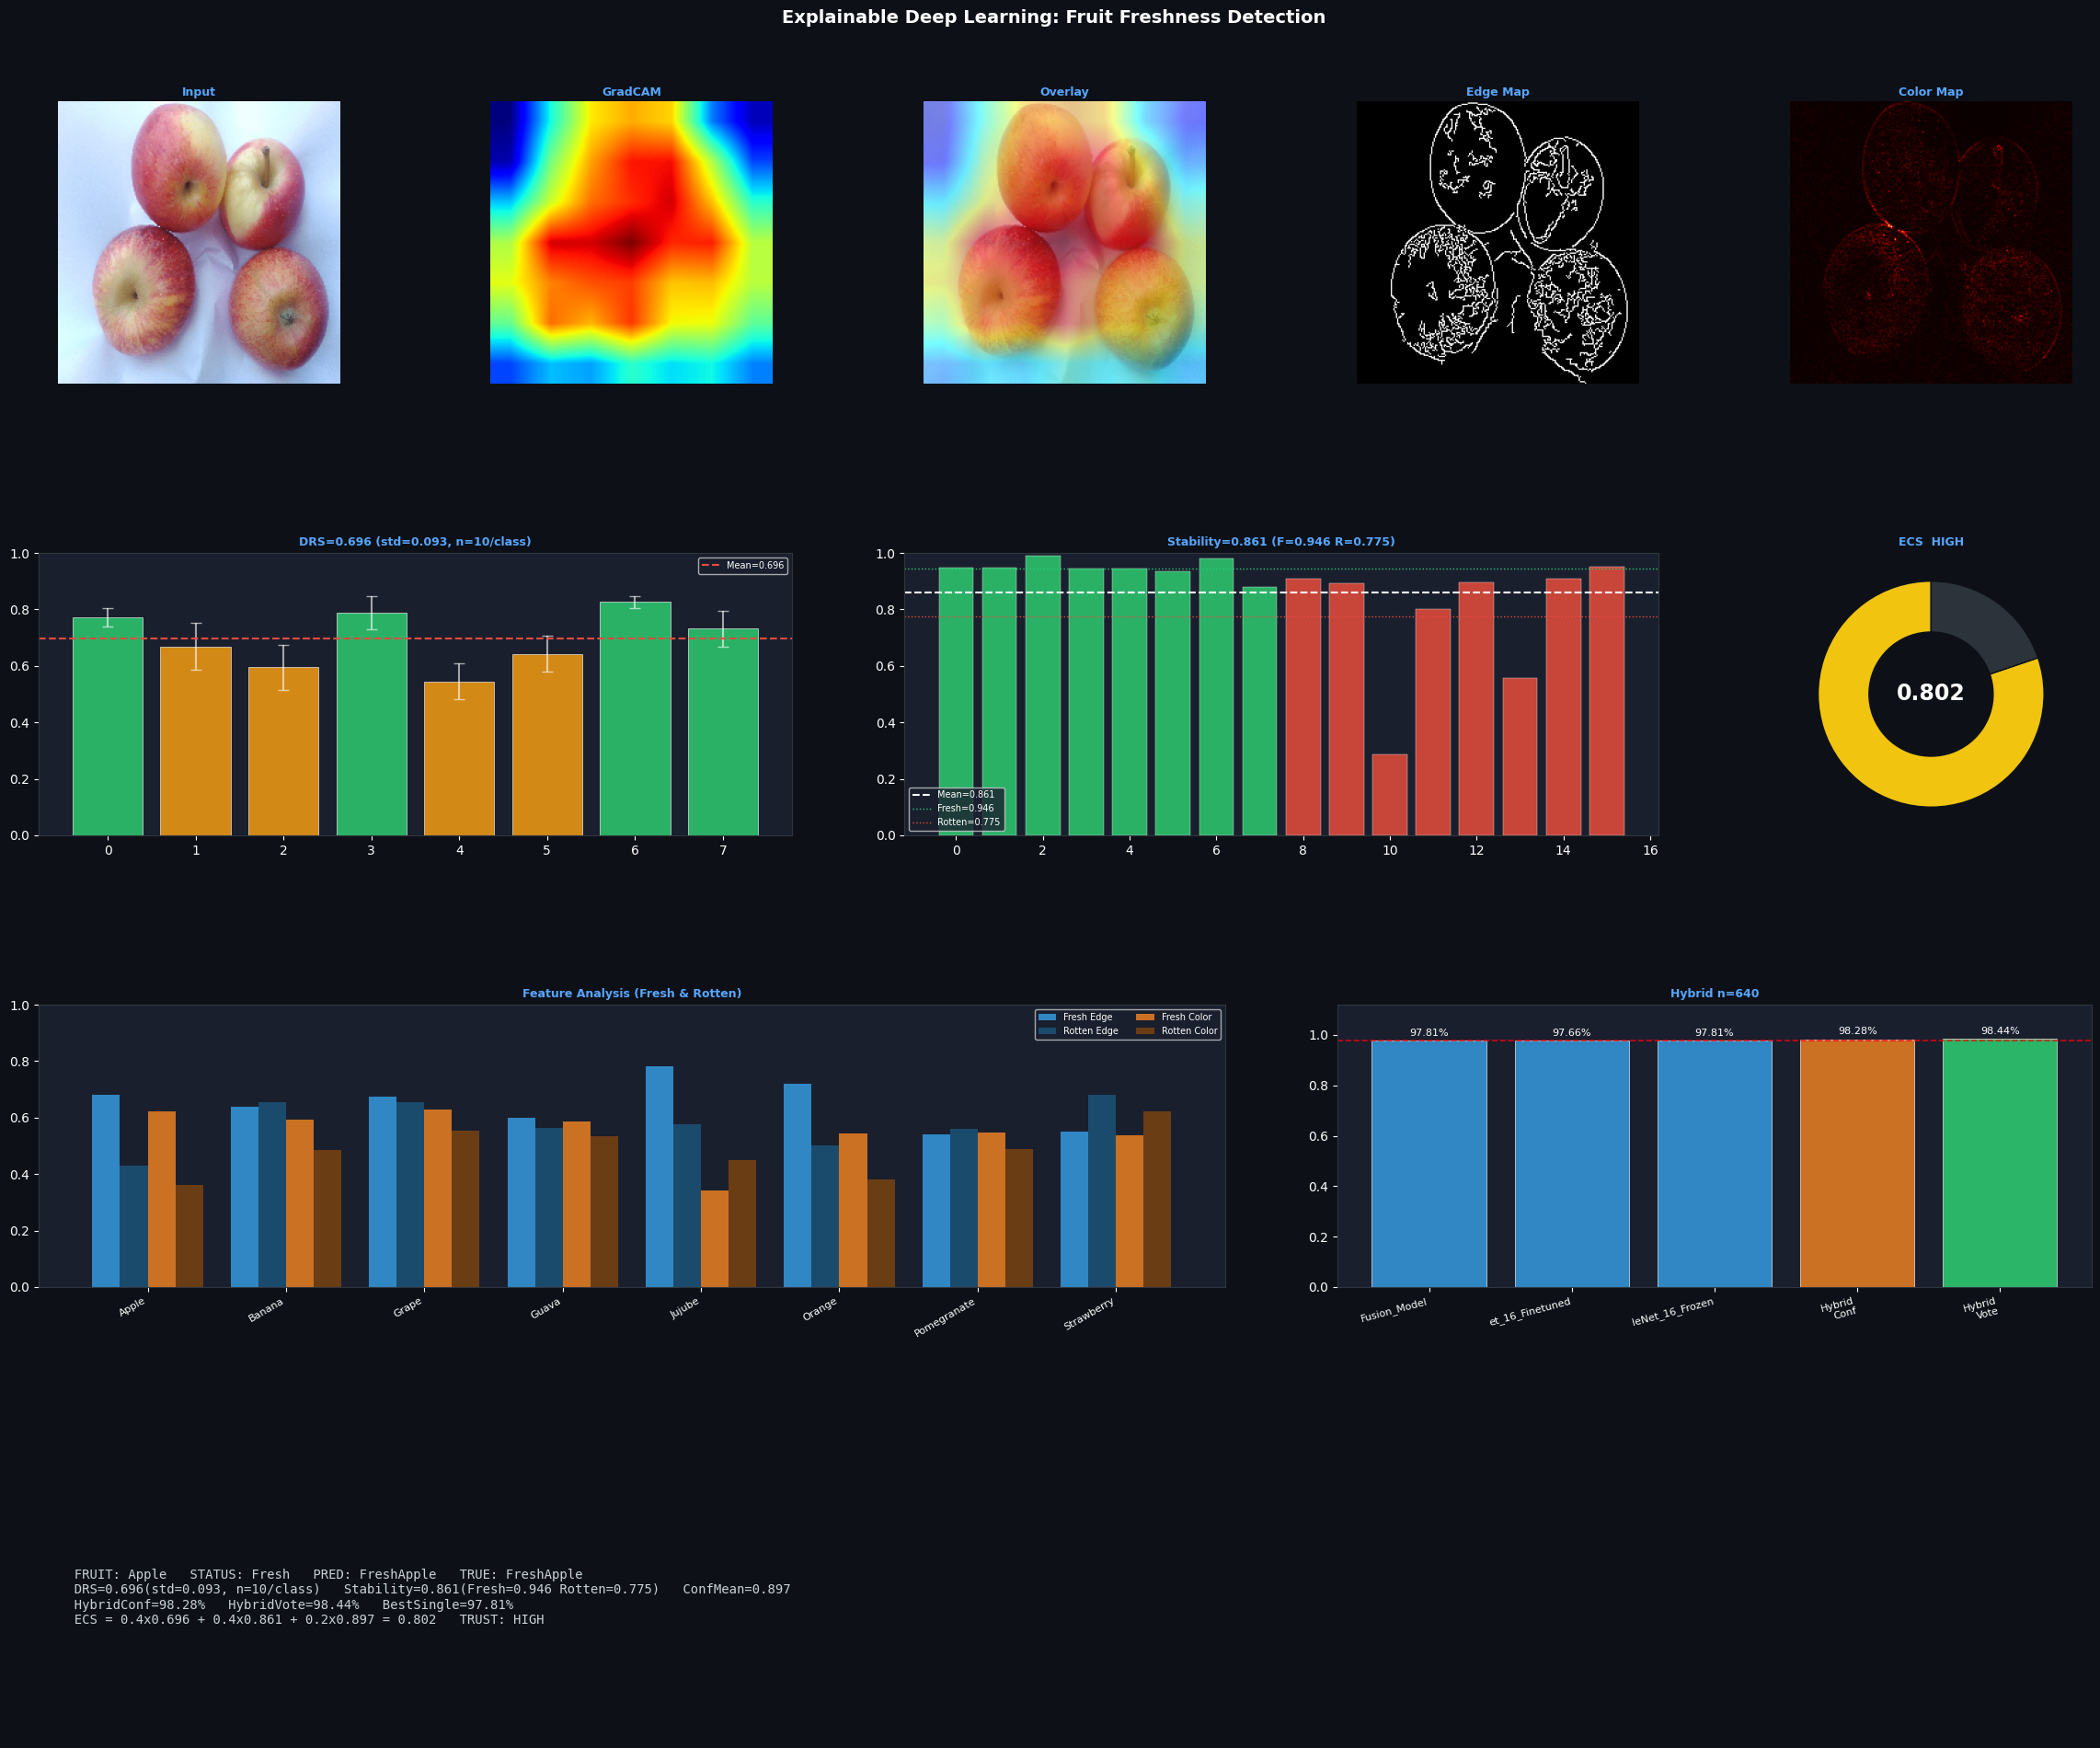

Saved: /content/drive/MyDrive/freshness_results_fixed/07_architecture.png
Saved: /content/drive/MyDrive/freshness_results_fixed/all_results.json

  FINAL RESULTS
  DRS             : 0.696  (std=0.093)
  Stability       : 0.861  Fresh=0.946  Rotten=0.775
  Hybrid Conf     : 98.28%
  Hybrid Vote     : 98.44%
  Best Single     : 97.81%
  ECS             : 0.802  ->  HIGH

Files saved:
  01_dataset_grid.png                                    2735.9 KB
  02_gradcam_16_classes.png                              3362.0 KB
  03_exp1_drs.png                                        2859.3 KB
  04_exp2_stability.png                                   103.0 KB
  05_exp3_features.png                                     87.7 KB
  06_exp4_hybrid.png                                       63.6 KB
  07_architecture.png                                    1201.1 KB
  all_results.json                                          6.7 KB

ALL DONE


In [ ]:
# FIX: ECS uses mean confidence across all 16 predictions (not just first image)
demo       = all_predictions[0]
fruit_name = demo['pred'].replace('Fresh','').replace('Rotten','')
freshness  = 'Fresh' if 'Fresh' in demo['pred'] else 'Rotten'

ECS = (0.4 * mean_drs
     + 0.4 * mean_stability
     + 0.2 * MEAN_CONFIDENCE)   # mean of all 16, not single image

trust = ('VERY HIGH' if ECS > 0.90 else
         'HIGH'      if ECS > 0.80 else
         'MODERATE'  if ECS > 0.65 else 'LOW')

print('ECS Calculation:')
print(f'  0.4 x DRS({mean_drs:.3f})  +  '
      f'0.4 x Stability({mean_stability:.3f})  +  '
      f'0.2 x ConfMean({MEAN_CONFIDENCE:.3f})')
print(f'  = {ECS:.3f}  ->  {trust}')

# Helper maps for architecture figure
def edge_map_fn(img):
    return cv2.Canny(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), 50, 150).astype('float32')/255

def color_map_fn(img):
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l   = cv2.split(lab)[0]
    v   = np.abs(cv2.Laplacian(l, cv2.CV_64F)).astype('float32')
    if v.max() > 0: v /= v.max()
    return v

d_img = demo['img_rgb']; d_hm = demo['heatmap']

# Architecture figure (dark theme)
fig = plt.figure(figsize=(24, 20))
fig.patch.set_facecolor('#0d1117')
gs  = gridspec.GridSpec(4, 5, figure=fig, hspace=0.6, wspace=0.35,
                        top=0.93, bottom=0.04, left=0.04, right=0.97)
fig.suptitle('Explainable Deep Learning: Fruit Freshness Detection',
             fontsize=14, fontweight='bold', color='white')

def da(ax, title):
    ax.set_facecolor('#1a1f2e')
    for sp in ax.spines.values(): sp.set_edgecolor('#30363d')
    ax.set_title(title, color='#58a6ff', fontsize=9, fontweight='bold', pad=4)
    ax.axis('off')

for col, (title, data, cmap) in enumerate([
        ('Input',    d_img,                       None),
        ('GradCAM',  d_hm,                        'jet'),
        ('Overlay',  overlay_heatmap(d_img, d_hm), None),
        ('Edge Map', edge_map_fn(d_img),           'gray'),
        ('Color Map',color_map_fn(d_img),          'hot')]):
    ax = fig.add_subplot(gs[0, col])
    ax.imshow(data, cmap=cmap) if cmap else ax.imshow(data)
    da(ax, title)

# DRS bar with error bars
ax_d = fig.add_subplot(gs[1, 0:2]); ax_d.set_facecolor('#1a1f2e')
dm   = [v['mean'] for v in drs_per_class.values()]
ds   = [v['std']  for v in drs_per_class.values()]
clrs = ['#2ecc71' if s > 0.7 else '#f39c12' for s in dm]
ax_d.bar(range(len(dm)), dm, color=clrs, alpha=0.85, edgecolor='white', lw=0.5,
         yerr=ds, capsize=4, error_kw={'ecolor':'white','alpha':0.6})
ax_d.axhline(mean_drs, color='#e74c3c', ls='--', lw=1.5,
             label=f'Mean={mean_drs:.3f}')
ax_d.set_ylim(0, 1); ax_d.tick_params(colors='white')
for sp in ax_d.spines.values(): sp.set_edgecolor('#30363d')
ax_d.set_title(f'DRS={mean_drs:.3f} (std={std_drs:.3f}, n={DRS_PER_CLASS}/class)',
               color='#58a6ff', fontsize=9, fontweight='bold')
ax_d.legend(fontsize=7, facecolor='#1a1f2e', labelcolor='white')

# Stability bar
ax_s = fig.add_subplot(gs[1, 2:4]); ax_s.set_facecolor('#1a1f2e')
sv   = stab_df['Stability'].values
sc2  = ['#2ecc71' if t == 'Fresh' else '#e74c3c' for t in stab_df['Type']]
ax_s.bar(range(len(sv)), sv, color=sc2, alpha=0.85, edgecolor='white', lw=0.3)
ax_s.axhline(mean_stability, color='white', ls='--', lw=1.5,
             label=f'Mean={mean_stability:.3f}')
ax_s.axhline(fresh_stab,  color='#2ecc71', ls=':', lw=1.0,
             label=f'Fresh={fresh_stab:.3f}')
ax_s.axhline(rotten_stab, color='#e74c3c', ls=':', lw=1.0,
             label=f'Rotten={rotten_stab:.3f}')
ax_s.set_ylim(0, 1); ax_s.tick_params(colors='white')
for sp in ax_s.spines.values(): sp.set_edgecolor('#30363d')
ax_s.set_title(f'Stability={mean_stability:.3f} '
               f'(F={fresh_stab:.3f} R={rotten_stab:.3f})',
               color='#58a6ff', fontsize=9, fontweight='bold')
ax_s.legend(fontsize=7, facecolor='#1a1f2e', labelcolor='white')

# ECS donut
ax_e = fig.add_subplot(gs[1, 4]); ax_e.set_facecolor('#1a1f2e')
ec = ('#2ecc71' if ECS>0.9 else '#f1c40f' if ECS>0.8
      else '#e67e22' if ECS>0.65 else '#e74c3c')
ax_e.pie([ECS, 1-ECS], colors=[ec, '#2d333b'],
         startangle=90, wedgeprops=dict(width=0.45, edgecolor='#0d1117'))
ax_e.text(0, 0, f'{ECS:.3f}', ha='center', va='center',
          fontsize=17, fontweight='bold', color='white')
ax_e.set_title(f'ECS  {trust}', color='#58a6ff', fontsize=9, fontweight='bold')

# Feature analysis
ax_f = fig.add_subplot(gs[2, 0:3]); ax_f.set_facecolor('#1a1f2e')
fl   = [c.replace('Fresh','') for c in fresh_classes]
xf   = np.arange(len(fl)); wf = 0.2
for ci, (mt, lbl, col) in enumerate([
        ('Edge',  'Fresh Edge',   '#3498db'), ('Edge',  'Rotten Edge',   '#1a5276'),
        ('Color', 'Fresh Color',  '#e67e22'), ('Color', 'Rotten Color',  '#784212')]):
    ft   = 'Fresh' if 'Fresh' in lbl else 'Rotten'
    vals = [feat_df[(feat_df['Fruit']==f) &
                    (feat_df['Type']==ft)][mt].values[0]
            for f in fl]
    ax_f.bar(xf + (ci-1.5)*wf, vals, wf, label=lbl, color=col, alpha=0.87)
ax_f.set_xticks(xf)
ax_f.set_xticklabels(fl, rotation=30, ha='right', fontsize=8, color='white')
ax_f.tick_params(colors='white'); ax_f.set_ylim(0, 1)
for sp in ax_f.spines.values(): sp.set_edgecolor('#30363d')
ax_f.set_title('Feature Analysis (Fresh & Rotten)',
               color='#58a6ff', fontsize=9, fontweight='bold')
ax_f.legend(fontsize=7, facecolor='#1a1f2e', labelcolor='white', ncol=2)

# Hybrid
ax_h = fig.add_subplot(gs[2, 3:5]); ax_h.set_facecolor('#1a1f2e')
hn   = ([n.replace('.keras','')[-15:] for n in model_accs]
        + ['Hybrid\nConf', 'Hybrid\nVote'])
hv   = list(model_accs.values()) + [hybrid_conf_acc, hybrid_vote_acc]
hc   = ['#3498db'] * len(model_accs) + ['#e67e22', '#2ecc71']
ax_h.bar(hn, hv, color=hc, alpha=0.87, edgecolor='white', lw=0.5)
ax_h.axhline(best_single, color='red', ls='--', lw=1.2, alpha=0.8)
ax_h.tick_params(colors='white'); ax_h.set_ylim(0, 1.12)
for sp in ax_h.spines.values(): sp.set_edgecolor('#30363d')
ax_h.set_title(f'Hybrid n={total_eval}',
               color='#58a6ff', fontsize=9, fontweight='bold')
for bar in ax_h.patches:
    ax_h.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.012,
              f'{bar.get_height():.2%}', ha='center', va='bottom',
              color='white', fontsize=8)
plt.setp(ax_h.get_xticklabels(), rotation=15, ha='right', fontsize=8, color='white')

# Report panel
ax_r = fig.add_subplot(gs[3, :]); ax_r.set_facecolor('#161b22')
for sp in ax_r.spines.values(): sp.set_edgecolor('#58a6ff'); sp.set_linewidth(2)
ax_r.axis('off')
rpt = (
    f'  FRUIT: {fruit_name}   STATUS: {freshness}   '
    f'PRED: {demo["pred"]}   TRUE: {demo["class"]}\n'
    f'  DRS={mean_drs:.3f}(std={std_drs:.3f}, n={DRS_PER_CLASS}/class)   '
    f'Stability={mean_stability:.3f}(Fresh={fresh_stab:.3f} Rotten={rotten_stab:.3f})   '
    f'ConfMean={MEAN_CONFIDENCE:.3f}\n'
    f'  HybridConf={hybrid_conf_acc:.2%}   '
    f'HybridVote={hybrid_vote_acc:.2%}   '
    f'BestSingle={best_single:.2%}\n'
    f'  ECS = 0.4x{mean_drs:.3f} + 0.4x{mean_stability:.3f} + '
    f'0.2x{MEAN_CONFIDENCE:.3f} = {ECS:.3f}   TRUST: {trust}'
)
ax_r.text(0.01, 0.5, rpt, transform=ax_r.transAxes,
          fontsize=10, color='#c9d1d9', va='center', fontfamily='monospace')

arch_p = os.path.join(SAVE_DIR, '07_architecture.png')
plt.savefig(arch_p, dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show(); print(f'Saved: {arch_p}')

# Save JSON
results = {
    'version': 'fixed_final',
    'drs_mean':  round(mean_drs,4),  'drs_std': round(std_drs,4),
    'drs_per_class': {k: {'mean': round(v['mean'],4), 'std': round(v['std'],4)}
                      for k, v in drs_per_class.items()},
    'stability_mean':   round(mean_stability,4),
    'stability_fresh':  round(fresh_stab,4),
    'stability_rotten': round(rotten_stab,4),
    'hybrid_conf_acc':  round(hybrid_conf_acc,4),
    'hybrid_vote_acc':  round(hybrid_vote_acc,4),
    'best_hybrid':      best_hybrid_name,
    'hybrid_samples':   total_eval,
    'model_accuracies': {k: round(v,4) for k, v in model_accs.items()},
    'binary_accuracies':{k: round(v,4) if v else None
                         for k, v in binary_results.items()},
    'mean_confidence':  round(MEAN_CONFIDENCE,4),
    'ecs':              round(ECS,4),
    'trust':            trust,
    'feature_analysis': feat_df.to_dict(orient='records'),
    'stability_table':  stab_df.to_dict(orient='records'),
}
json_p = os.path.join(SAVE_DIR, 'all_results.json')
with open(json_p, 'w') as f: json.dump(results, f, indent=2)
print(f'Saved: {json_p}')

print('\n' + '='*65)
print('  FINAL RESULTS')
print('='*65)
print(f'  DRS             : {mean_drs:.3f}  (std={std_drs:.3f})')
print(f'  Stability       : {mean_stability:.3f}  '
      f'Fresh={fresh_stab:.3f}  Rotten={rotten_stab:.3f}')
print(f'  Hybrid Conf     : {hybrid_conf_acc:.2%}')
print(f'  Hybrid Vote     : {hybrid_vote_acc:.2%}')
print(f'  Best Single     : {best_single:.2%}')
print(f'  ECS             : {ECS:.3f}  ->  {trust}')
print('='*65)
print('\nFiles saved:')
for fn in sorted(os.listdir(SAVE_DIR)):
    sz = os.path.getsize(os.path.join(SAVE_DIR, fn))/1024
    print(f'  {fn:<54} {sz:6.1f} KB')
print('\nALL DONE')
